# CSE 242 - Assignment 1
### Linear algebra, probability, estimation, and PCA

[Assignment source](https://github.com/ucsc-cse-242/assignments/blob/main/Assignment1/README.md)

**AI-use disclosure:** The disclosure and deidentified conversation transcript are provided in the separate companion file `ai-disclosure-and-transcripts.pdf`.

Run this notebook from top to bottom to reproduce the results.

The mathematical solutions precede the numerical experiment. In Part 3,
observations occupy rows and features occupy columns; sample covariances use
the denominator $n-1$.

## Environment

In [1]:
import sys
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

SEED = 242
np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({
    "figure.figsize": (6, 4), "figure.dpi": 130,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18,
})
print(f"Python {sys.version.split()[0]}")
print(f"NumPy {np.__version__}; Matplotlib {matplotlib.__version__}")

Python 3.13.12
NumPy 2.5.3; Matplotlib 3.11.2


## Part 1 - Linear algebra

### Q1 - Matrix operations

With $A=\begin{bmatrix}3&4\\2&1\end{bmatrix}$ and
$B=\begin{bmatrix}1&2\\0&-1\end{bmatrix}$, each entry of a product
is a row-column dot product:

$$
AB=\begin{bmatrix}
3(1)+4(0)&3(2)+4(-1)\\
2(1)+1(0)&2(2)+1(-1)
\end{bmatrix}
=\boxed{\begin{bmatrix}3&2\\2&3\end{bmatrix}}.
$$

$$
BA=\begin{bmatrix}
1(3)+2(2)&1(4)+2(1)\\
0(3)-1(2)&0(4)-1(1)
\end{bmatrix}
=\boxed{\begin{bmatrix}7&6\\-2&-1\end{bmatrix}}.
$$

For the sum and transpose,
$$
A+B=\begin{bmatrix}4&6\\2&0\end{bmatrix},
\qquad (A+B)^T=\boxed{\begin{bmatrix}4&2\\6&0\end{bmatrix}}.
$$

Because $B^T=\begin{bmatrix}1&0\\2&-1\end{bmatrix}$,
$$
AB^T=\begin{bmatrix}
3(1)+4(2)&3(0)+4(-1)\\
2(1)+1(2)&2(0)+1(-1)
\end{bmatrix}
=\boxed{\begin{bmatrix}11&-4\\4&-1\end{bmatrix}}.
$$

The trace sums diagonal entries:
$$\boxed{\operatorname{tr}(A)=3+1=4},\qquad
\boxed{\operatorname{tr}(AB)=3+3=6}.$$
The different products $AB$ and $BA$ illustrate that matrix multiplication
need not commute.

### Q2 - Eigenvalues and eigenvectors

For $M=\begin{bmatrix}2&-1\\-1&2\end{bmatrix}$, a nonzero vector
$v$ solves $(M-\lambda I)v=0$ only if
$$
\det(M-\lambda I)=(2-\lambda)^2-1
=\lambda^2-4\lambda+3=(\lambda-1)(\lambda-3)=0.
$$
Thus the eigenvalues are $\boxed{1,3}$.

For $\lambda=1$, the equation $v_1-v_2=0$ gives equal coordinates.
Choose the unit vector $u_1=(1,1)^T/\sqrt{2}$. For $\lambda=3$,
the equation $-v_1-v_2=0$ gives opposite coordinates.
Choose $u_2=(1,-1)^T/\sqrt{2}$. Any nonzero multiple of either
vector is an eigenvector for the corresponding eigenvalue.

Direct verification gives
$$
Mu_1=\frac1{\sqrt2}\begin{bmatrix}2-1\\-1+2\end{bmatrix}
=\frac1{\sqrt2}\begin{bmatrix}1\\1\end{bmatrix}=1u_1,
$$
$$
Mu_2=\frac1{\sqrt2}\begin{bmatrix}2+1\\-1-2\end{bmatrix}
=\frac1{\sqrt2}\begin{bmatrix}3\\-3\end{bmatrix}=3u_2.
$$

### Q3 - Trace identity proof

More generally, let $A\in\mathbb{R}^{m\times n}$ and
$B\in\mathbb{R}^{n\times m}$, so both $AB$ and $BA$ are square.
By the definitions of matrix multiplication and trace,
$$
\begin{aligned}
\operatorname{tr}(AB)
&=\sum_{i=1}^{m}(AB)_{ii}\\
&=\sum_{i=1}^{m}\sum_{j=1}^{n}A_{ij}B_{ji}\\
&=\sum_{j=1}^{n}\sum_{i=1}^{m}B_{ji}A_{ij}\\
&=\sum_{j=1}^{n}(BA)_{jj}
=\operatorname{tr}(BA).
\end{aligned}
$$
The third line interchanges finite sums and commutes scalar multiplication;
it does not assume that matrices commute. Hence
$\boxed{\operatorname{tr}(AB)=\operatorname{tr}(BA)}$.

### Q4 - Matrix inverse

For $C=\begin{bmatrix}4&7\\2&6\end{bmatrix}$,
$$\det(C)=4(6)-7(2)=24-14=10\ne0.$$
The nonzero determinant establishes that the inverse exists. For a
$2\times2$ matrix, swap the diagonal entries, negate the off-diagonal
entries, and divide by the determinant:
$$
\boxed{C^{-1}=\frac1{10}\begin{bmatrix}6&-7\\-2&4\end{bmatrix}
=\begin{bmatrix}0.6&-0.7\\-0.2&0.4\end{bmatrix}}.
$$
To verify the calculation on both sides,
$$
CC^{-1}=\frac1{10}\begin{bmatrix}24-14&-28+28\\12-12&-14+24\end{bmatrix}=I,
$$
$$
C^{-1}C=\frac1{10}\begin{bmatrix}24-14&42-42\\-8+8&-14+24\end{bmatrix}=I.
$$

## Part 2 - Probability, MLE, and MAP

### Q1 - Normalization, expectation, and variance

**(a) Normalization.** The mass function is $p(k)=c3^k/k!$ for
nonnegative integers. Using the exponential series,
$$
1=\sum_{k=0}^{\infty}c\frac{3^k}{k!}=ce^3
\quad\Longrightarrow\quad \boxed{c=e^{-3}}.
$$
All probabilities are nonnegative. This is a Poisson distribution with
parameter $3$, but the moments can also be derived directly.

**(b) Moments.** Cancel $k$ against $k!$ and reindex with $j=k-1$:
$$
\begin{aligned}
E[X]&=e^{-3}\sum_{k=1}^{\infty}\frac{k3^k}{k!}
=3e^{-3}\sum_{k=1}^{\infty}\frac{3^{k-1}}{(k-1)!}\\
&=3e^{-3}\sum_{j=0}^{\infty}\frac{3^j}{j!}=3.
\end{aligned}
$$
Similarly, using $j=k-2$,
$$
\begin{aligned}
E[X(X-1)]
&=e^{-3}\sum_{k=2}^{\infty}\frac{k(k-1)3^k}{k!}\\
&=9e^{-3}\sum_{j=0}^{\infty}\frac{3^j}{j!}=9.
\end{aligned}
$$
Since $X^2=X(X-1)+X$,
$$E[X^2]=9+3=12,$$
$$\boxed{E[X]=3},\qquad
\boxed{\operatorname{Var}(X)=E[X^2]-E[X]^2=12-9=3}.$$

### Q2 - Event probabilities

The supplied probabilities are $P(A)=0.5$, $P(B)=0.3$, and
$P(A\mid B)=0.6$.

**(a) Intersection.** The definition of conditional probability yields
$$\boxed{P(A\cap B)=P(A\mid B)P(B)=0.6(0.3)=0.18}.$$

**(b) Reverse conditional probability.**
$$\boxed{P(B\mid A)=\frac{P(A\cap B)}{P(A)}
=\frac{0.18}{0.5}=0.36}.$$

**(c) Union.** Inclusion-exclusion removes the intersection counted twice:
$$\boxed{P(A\cup B)=P(A)+P(B)-P(A\cap B)
=0.5+0.3-0.18=0.62}.$$

### Q3 - Coin MLE and MAP

Assume independent flips with the same head probability $\theta\in[0,1]$.
The observed sequence has three heads and two tails.

**(a) Maximum likelihood.** The likelihood of this ordered sequence is
$$L(\theta)=\theta^3(1-\theta)^2.$$
A binomial coefficient would be needed for an unordered count, but would
be constant in $\theta$ and would not change its maximizer.
For $0<\theta<1$, the log-likelihood and derivatives are
$$\ell(\theta)=3\log\theta+2\log(1-\theta),$$
$$\ell'(\theta)=\frac3\theta-\frac2{1-\theta}=0
\quad\Longrightarrow\quad3(1-\theta)=2\theta,$$
$$\boxed{\widehat\theta_{\mathrm{MLE}}=\frac35=0.6}.$$
Because $\ell''(\theta)=-3/\theta^2-2/(1-\theta)^2<0$,
this is the unique interior maximum. The likelihood is zero at both
endpoints, confirming the global maximum.

**(b) Maximum a posteriori.** The given prior has density $p(\theta)=2\theta$
on $[0,1]$. Bayes' rule gives
$$p(\theta\mid D)\propto L(\theta)p(\theta)
=2\theta^4(1-\theta)^2.$$
Its log-density, up to a constant, is
$$g(\theta)=4\log\theta+2\log(1-\theta)+\text{constant}.$$
Thus
$$g'(\theta)=\frac4\theta-\frac2{1-\theta}=0
\quad\Longrightarrow\quad4(1-\theta)=2\theta,$$
$$\boxed{\widehat\theta_{\mathrm{MAP}}=\frac23\approx0.6667}.$$
Here $g''(\theta)=-4/\theta^2-2/(1-\theta)^2<0$, and the
posterior density vanishes at both endpoints. This verifies the global
maximum. The increasing prior favors larger head probabilities, so the
MAP estimate exceeds the MLE. The posterior is $\operatorname{Beta}(5,3)$;
MAP is its mode, not its mean.

### Q4 - Gaussian MLE

Assume $x_1,\ldots,x_n$ are independent observations from
$\mathcal N(\mu,\sigma^2)$ with $\sigma^2>0$. Write $s=\sigma^2$.
The likelihood is
$$L(\mu,s)=(2\pi s)^{-n/2}
\exp\left[-\frac1{2s}\sum_{i=1}^{n}(x_i-\mu)^2\right].$$
Taking logarithms,
$$\ell(\mu,s)=-\frac n2\log(2\pi)-\frac n2\log s
-\frac1{2s}\sum_{i=1}^{n}(x_i-\mu)^2.$$
First differentiate with respect to the mean:
$$\frac{\partial\ell}{\partial\mu}
=\frac1s\sum_{i=1}^{n}(x_i-\mu)=0
\quad\Longrightarrow\quad\widehat\mu=\bar x.$$
For every fixed $s>0$, $\partial^2\ell/\partial\mu^2=-n/s<0$,
so the sample mean is the unique maximizing mean.

Next differentiate with respect to the variance:
$$\frac{\partial\ell}{\partial s}
=-\frac n{2s}+\frac{\sum_i(x_i-\mu)^2}{2s^2}=0.$$
Substituting $\mu=\bar x$ and rearranging yields
$$\widehat{\sigma^2}_{\mathrm{MLE}}
=\frac1n\sum_{i=1}^{n}(x_i-\bar x)^2.$$
For the data $\{1,3,5,7\}$,
$$\boxed{\widehat\mu_{\mathrm{MLE}}=\frac{1+3+5+7}{4}=4},$$
$$S=\sum_i(x_i-4)^2=9+1+1+9=20,$$
$$\boxed{\widehat{\sigma^2}_{\mathrm{MLE}}=\frac{20}{4}=5}.$$
The profile log-likelihood derivative is $(S-ns)/(2s^2)$:
it is positive below $S/n$ and negative above $S/n$. Since $S=20>0$,
this confirms the unique joint maximum. The MLE uses denominator $n$;
the unbiased sample variance instead uses $n-1$ and would be $20/3$.

### Q5 - Gaussian mean MAP

The single observation is $x=5$, the likelihood variance is $4$, and
the prior is $\mu\sim\mathcal N(0,1)$. Up to constants independent of $\mu$,
$$p(\mu\mid x=5)\propto
\exp\left[-\frac{(5-\mu)^2}{8}-\frac{\mu^2}{2}\right].$$
The derivative of its log-density is
$$\frac{d}{d\mu}\log p(\mu\mid x=5)
=\frac{5-\mu}{4}-\mu.$$
Setting this equal to zero gives $5-\mu-4\mu=0$, hence
$$\boxed{\widehat\mu_{\mathrm{MAP}}=1}.$$
The second derivative is $-1/4-1=-5/4<0$, so the stationary point is
the unique maximum. Completing the square provides a second check:
$$-\frac{(5-\mu)^2}{8}-\frac{\mu^2}{2}
=-\frac58(\mu-1)^2-\frac52.$$
Therefore the posterior is $\mathcal N(1,4/5)$. Its center is the
precision-weighted average $(5/4+0/1)/(1/4+1)=1$; the relatively
concentrated prior pulls the estimate toward zero.

### Q6 - Variance identity proof

Assume $E[X^2]<\infty$ and let $m=E[X]$, a constant. Expanding the
definition and using linearity of expectation,
$$
\begin{aligned}
\operatorname{Var}(X)
&=E[(X-m)^2]\\
&=E[X^2-2mX+m^2]\\
&=E[X^2]-2mE[X]+m^2\\
&=E[X^2]-2m^2+m^2\\
&=\boxed{E[X^2]-[E[X]]^2}.
\end{aligned}
$$

## Part 3 - Principal component analysis

### Q1 - Projection variance derivation

Let $X\in\mathbb R^d$ be a random **column** vector with finite second
moments, mean $\mu=E[X]$, and covariance matrix
$$\Sigma=E[(X-\mu)(X-\mu)^T],\qquad
\Sigma_{ij}=E[(X_i-\mu_i)(X_j-\mu_j)].$$
Let $u\in\mathbb R^d$ be a fixed unit vector, $u^Tu=1$, and define the
scalar projection $Y=u^TX$. Its mean is $E[Y]=u^T\mu$. Consequently,
$$
\begin{aligned}
\operatorname{Var}(u^TX)
&=E[(u^TX-u^T\mu)^2]\\
&=E[(u^T(X-\mu))^2]\\
&=E[(u^T(X-\mu))((X-\mu)^Tu)]\\
&=E[u^T(X-\mu)(X-\mu)^Tu]\\
&=u^TE[(X-\mu)(X-\mu)^T]u\\
&=\boxed{u^T\Sigma u}.
\end{aligned}
$$
The third line uses the fact that a scalar equals its transpose. The
fifth moves the fixed vector outside the expectation. The identity holds
for any fixed $u$; the unit constraint makes variances across directions
comparable without an arbitrary scaling factor.

**Connection to PCA.** Maximizing $u^T\Sigma u$ subject to $u^Tu=1$
gives the Lagrangian
$$\mathcal L(u,\lambda)=u^T\Sigma u-\lambda(u^Tu-1).$$
Since $\Sigma$ is symmetric, stationarity implies
$2\Sigma u-2\lambda u=0$, or $\Sigma u=\lambda u$.
For a unit eigenvector, $u^T\Sigma u=\lambda$. More generally, expanding
a unit vector in an orthonormal eigenbasis gives a weighted average
of the eigenvalues, so no direction exceeds the largest eigenvalue.
PCA therefore selects eigenvectors in descending eigenvalue order.

### Q2 - Correlated synthetic data

Generate $n=500$ independent observations from a two-dimensional Gaussian:
$$\mu_0=\begin{bmatrix}2\\-1\end{bmatrix},\qquad
\Sigma_0=\begin{bmatrix}4&3.2\\3.2&4\end{bmatrix}.$$
The covariance is positive definite (eigenvalues $7.2$ and $0.8$).
Its population correlation is $3.2/\sqrt{4\cdot4}=0.8$.
The features share a scale and comparable marginal variance, so the
experiment uses covariance PCA without standardizing each feature.
A fixed random seed makes the finite sample reproducible.

In [2]:
# Reset the generator here so rerunning this cell reproduces the data.
rng = np.random.default_rng(SEED)
n = 500
population_mean = np.array([2.0, -1.0])
population_cov = np.array([[4.0, 3.2], [3.2, 4.0]])
X = rng.multivariate_normal(population_mean, population_cov, size=n)
sample_correlation = np.corrcoef(X, rowvar=False)[0, 1]

print("Data shape:", X.shape)
print("Sample feature means:", X.mean(axis=0))
print(f"Sample correlation: {sample_correlation:.6f}")

Data shape: (500, 2)
Sample feature means: [ 2.056749 -0.925068]
Sample correlation: 0.815132


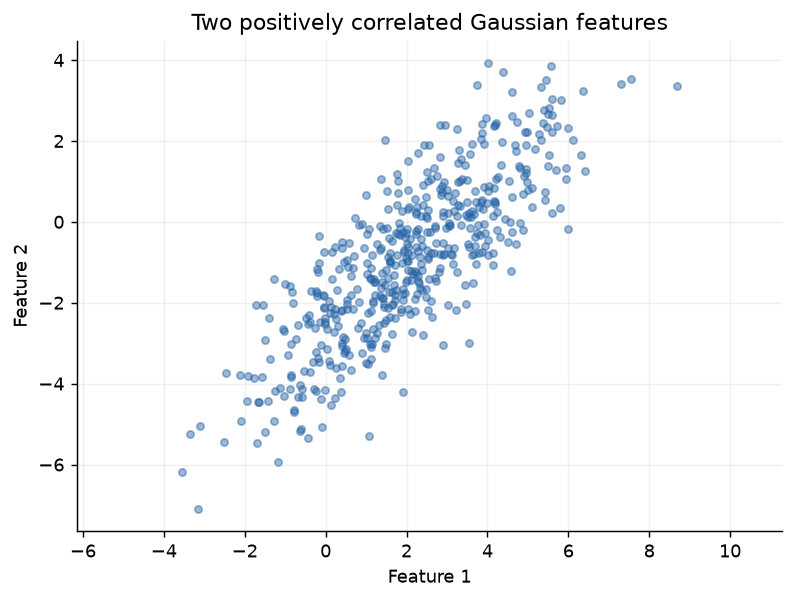

In [3]:
fig, ax = plt.subplots(figsize=(6, 4.5), layout="constrained")
ax.scatter(X[:, 0], X[:, 1], s=16, alpha=0.45, color="#2563a6")
ax.set(xlabel="Feature 1", ylabel="Feature 2",
       title="Two positively correlated Gaussian features")
ax.set_aspect("equal", adjustable="datalim")
plt.show()

In [4]:
display(Markdown(
    f"The sample correlation is **{sample_correlation:.3f}**, close to "
    "the population value of 0.8. The upward-sloping, elongated cloud "
    "shows that larger values of feature 1 tend to accompany larger "
    "values of feature 2. The finite width perpendicular to that trend "
    "shows that the relationship is not exact. Sampling variation "
    "explains why the measured correlation is not precisely 0.8."
))

The sample correlation is **0.815**, close to the population value of 0.8. The upward-sloping, elongated cloud shows that larger values of feature 1 tend to accompany larger values of feature 2. The finite width perpendicular to that trend shows that the relationship is not exact. Sampling variation explains why the measured correlation is not precisely 0.8.

### Q3 - PCA implementation and principal directions

For the observed matrix $X\in\mathbb R^{n\times d}$, form the sample
mean $\bar x$ and centered matrix $X_c$. The sample analogue of the
covariance in Q1 is
$$\widehat\Sigma=\frac{1}{n-1}X_c^TX_c.$$
The $n-1$ convention estimates the population covariance after estimating
the mean. Using $n$ would rescale all eigenvalues equally, leaving
eigenvectors and explained-variance proportions unchanged.

Compute the eigendecomposition of this symmetric matrix with
`numpy.linalg.eigh`, sort the eigenpairs in descending order, and retain
the first $k$ eigenvectors as columns of $U_k$. The coordinates and
reconstruction are
$$Z_k=X_cU_k,\qquad \widehat X_k=Z_kU_k^T+\bar x.$$
The function below implements these steps directly in NumPy. Each score
column has sample variance $u_j^T\widehat\Sigma u_j=\lambda_j$,
which is the empirical version of the derivation in Q1.

In [5]:
def fit_pca(data):
    """Fit all components using centered sample covariance and eigh.

    Rows are observations. Component directions are columns.
    No PCA estimator or covariance helper is used in the fit.
    """
    data = np.asarray(data, dtype=float)
    if data.ndim != 2 or data.shape[0] < 2:
        raise ValueError("Expected a 2D array with at least two rows.")
    if data.shape[1] == 0 or not np.isfinite(data).all():
        raise ValueError("Expected finite data with at least one feature.")

    mean = data.mean(axis=0)                  # 1. Estimate the mean.
    centered = data - mean                   # 2. Center each feature.
    covariance = centered.T @ centered / (len(data) - 1)
    eigenvalues, components = np.linalg.eigh(covariance)
    order = np.argsort(eigenvalues)[::-1]     # 3. Sort by variance.
    eigenvalues = eigenvalues[order]
    components = components[:, order]

    # Fix arbitrary signs for reproducible plots and printed directions.
    for j in range(components.shape[1]):
        largest = np.argmax(np.abs(components[:, j]))
        if components[largest, j] < 0:
            components[:, j] *= -1

    scores = centered @ components          # 4. Project onto all PCs.
    return mean, centered, covariance, eigenvalues, components, scores


mean, Xc, covariance, eigenvalues, components, scores = fit_pca(X)
k = 1
U_k = components[:, :k]                     # Retain the leading PC.
Z_k = Xc @ U_k
X_reconstructed = Z_k @ U_k.T + mean

print("Sample covariance:\n", covariance)
print("Eigenvalues (descending):", eigenvalues)
print("Principal directions (columns):\n", components)
print("Reduced data shape:", Z_k.shape)

Sample covariance:
 [[4.013039 3.258854]
 [3.258854 3.982912]]
Eigenvalues (descending): [7.256864 0.739087]
Principal directions (columns):
 [[ 0.708739 -0.705471]
 [ 0.705471  0.708739]]
Reduced data shape: (500, 1)


The left plot overlays both principal directions on the original data.
Each arrow starts at the sample mean and extends two standard deviations
($2\sqrt{\lambda_j}$) along its eigenvector. Arrow lengths convey spread;
the directions themselves are unit vectors. The right plot displays the
same observations in the rotated, centered PC coordinate system.

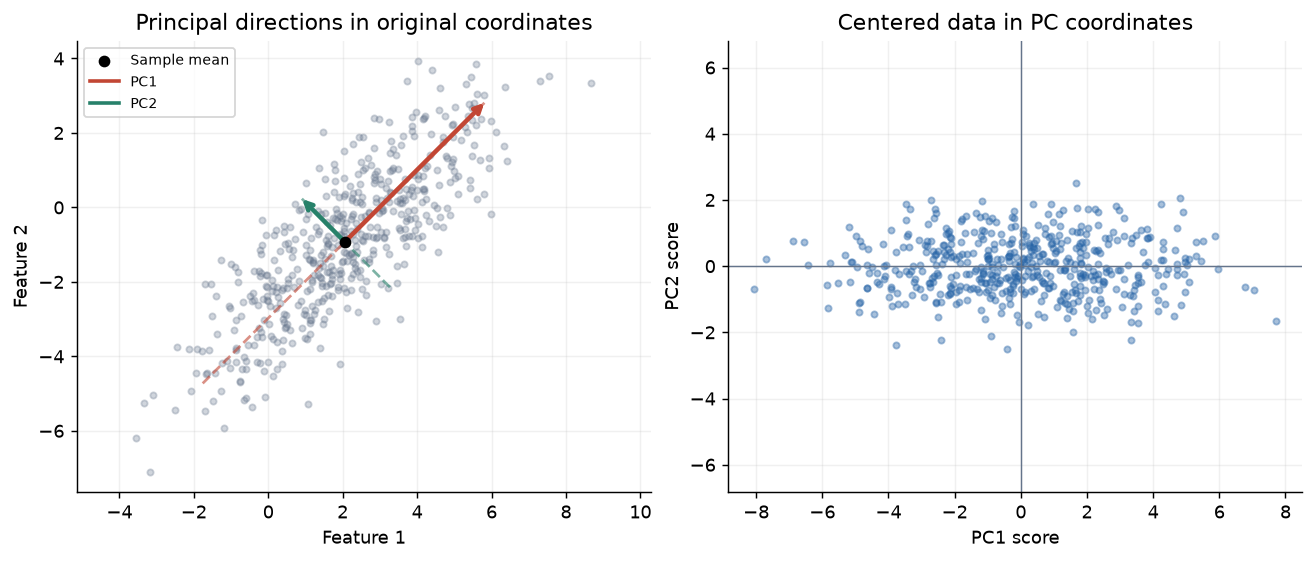

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
colors = ["#c24634", "#27816a"]
axes[0].scatter(X[:, 0], X[:, 1], s=12, alpha=0.3, color="#64748b")
axes[0].scatter(*mean, c="black", s=30, zorder=5, label="Sample mean")
for j, color in enumerate(colors):
    delta = 2 * np.sqrt(eigenvalues[j]) * components[:, j]
    endpoints = np.vstack([mean - delta, mean + delta])
    axes[0].plot(endpoints[:, 0], endpoints[:, 1], "--", color=color,
                 alpha=0.6)
    axes[0].annotate("", xy=mean + delta, xytext=mean,
                     arrowprops={"arrowstyle": "->", "lw": 2.5,
                                 "color": color})
    axes[0].plot([], [], color=color, lw=2, label=f"PC{j + 1}")
axes[0].set(xlabel="Feature 1", ylabel="Feature 2",
            title="Principal directions in original coordinates")
axes[0].legend(loc="upper left", fontsize=8)

axes[1].scatter(scores[:, 0], scores[:, 1], s=12, alpha=0.4,
                color="#2563a6")
axes[1].axhline(0, color="#64748b", lw=0.8)
axes[1].axvline(0, color="#64748b", lw=0.8)
axes[1].set(xlabel="PC1 score", ylabel="PC2 score",
            title="Centered data in PC coordinates")
for ax in axes:
    ax.set_aspect("equal", adjustable="datalim")
plt.show()

The first component follows the elongated direction of the data; the
second is orthogonal and captures the smaller transverse spread. Centering
removes the translation of the cloud, and rotation decorrelates the score
columns. Reversing an eigenvector's sign reverses its scores but leaves
the represented axis, explained variance, and reconstruction unchanged.

**Numerical verification.** The following checks compare against an
independent SVD of the centered data, test the eigenvector equations,
and check the variance and reconstruction identities. `np.cov` is used
only here as a cross-check of the hand-assembled covariance.

In [7]:
np.testing.assert_allclose(Xc.mean(axis=0), 0, atol=1e-12)
np.testing.assert_allclose(covariance, covariance.T, atol=1e-12)
np.testing.assert_allclose(covariance, np.cov(X, rowvar=False))
np.testing.assert_allclose(components.T @ components, np.eye(2),
                           atol=1e-12)
np.testing.assert_allclose(covariance @ components,
                           components * eigenvalues, atol=1e-12)
np.testing.assert_allclose(np.cov(scores, rowvar=False),
                           np.diag(eigenvalues), atol=1e-12)

singular_values = np.linalg.svd(Xc, compute_uv=False)
np.testing.assert_allclose(eigenvalues, singular_values**2 / (n - 1))
np.testing.assert_allclose(scores @ components.T + mean, X,
                           atol=1e-12)
assert np.all(eigenvalues > 0)
assert np.all(np.diff(eigenvalues) <= 0)
print("All PCA covariance, eigenpair, SVD, and reconstruction checks pass.")

All PCA covariance, eigenpair, SVD, and reconstruction checks pass.


### Q4 - Explained variance and dimensionality reduction

An orthonormal change of coordinates preserves total variance, which is
the trace of the covariance. Consequently,
$$\text{EVR}_j=\frac{\lambda_j}{\sum_{r=1}^{d}\lambda_r},\qquad
\text{retained fraction for }k\text{ PCs}=\sum_{j=1}^{k}\text{EVR}_j.$$
The population covariance chosen in Q2 has variance proportions
$7.2/8=90\%$ and $0.8/8=10\%$. The code computes the actual finite-sample
proportions rather than substituting these population values.

In [8]:
explained_ratio = eigenvalues / eigenvalues.sum()
cumulative_ratio = np.cumsum(explained_ratio)
residuals = X - X_reconstructed
sse = np.sum(residuals**2)
mean_squared_distance = sse / n
lost_fraction = 1 - explained_ratio[:k].sum()

np.testing.assert_allclose(explained_ratio.sum(), 1.0)
np.testing.assert_allclose(eigenvalues.sum(), np.trace(covariance))
np.testing.assert_allclose(sse / (n - 1), eigenvalues[k:].sum())
np.testing.assert_allclose(residuals @ U_k, 0, atol=1e-12)
np.testing.assert_allclose(sse / np.sum(Xc**2), lost_fraction)

display(Markdown(
    "| Component | Sample variance | Explained | Cumulative |\n"
    "|:---|---:|---:|---:|\n" + "\n".join(
        f"| PC{j+1} | {eigenvalues[j]:.6f} | "
        f"{100 * explained_ratio[j]:.2f}% | "
        f"{100 * cumulative_ratio[j]:.2f}% |"
        for j in range(len(eigenvalues))
    )
))
print(f"Mean squared Euclidean reconstruction error: "
      f"{mean_squared_distance:.6f}")

| Component | Sample variance | Explained | Cumulative |
|:---|---:|---:|---:|
| PC1 | 7.256864 | 90.76% | 90.76% |
| PC2 | 0.739087 | 9.24% | 100.00% |

Mean squared Euclidean reconstruction error: 0.737609


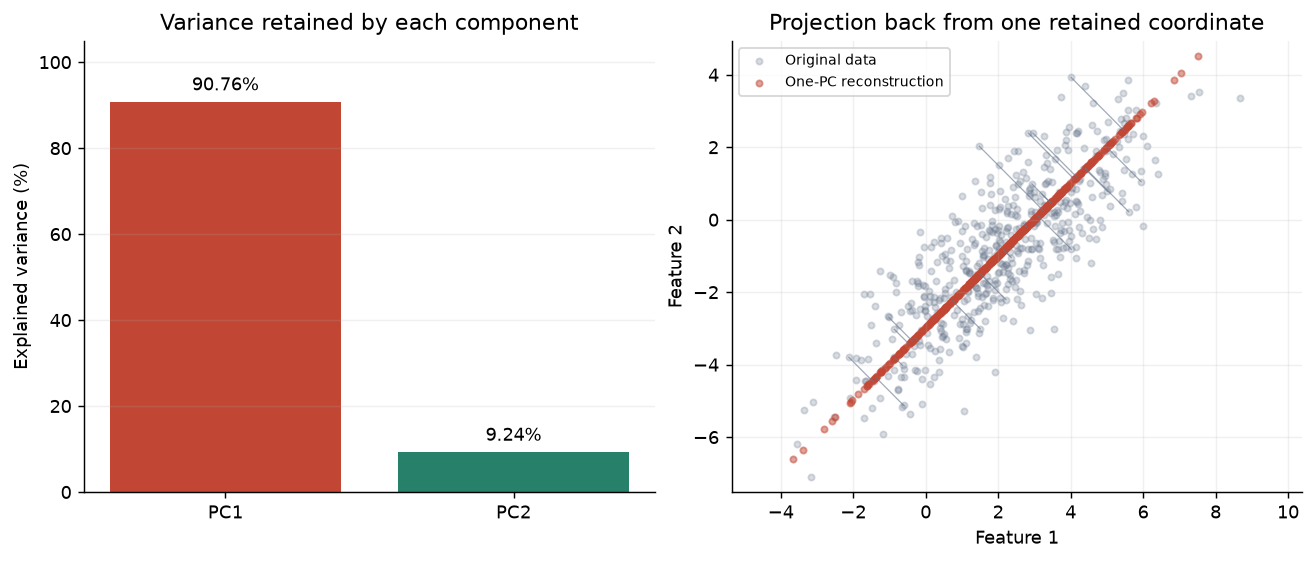

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
bars = axes[0].bar(["PC1", "PC2"], 100 * explained_ratio, color=colors)
axes[0].bar_label(bars, fmt="%.2f%%", padding=4)
axes[0].set(ylim=(0, 105), ylabel="Explained variance (%)",
            title="Variance retained by each component")
axes[0].grid(axis="x", visible=False)

axes[1].scatter(X[:, 0], X[:, 1], s=12, alpha=0.25,
                color="#64748b", label="Original data")
axes[1].scatter(X_reconstructed[:, 0], X_reconstructed[:, 1],
                s=12, alpha=0.5, color=colors[0], label="One-PC reconstruction")
# A subset of perpendicular residual segments makes the loss visible.
for i in range(0, n, 25):
    axes[1].plot([X[i, 0], X_reconstructed[i, 0]],
                 [X[i, 1], X_reconstructed[i, 1]],
                 color="#64748b", lw=0.7, alpha=0.6)
axes[1].set(xlabel="Feature 1", ylabel="Feature 2",
            title="Projection back from one retained coordinate")
axes[1].set_aspect("equal", adjustable="datalim")
axes[1].legend(loc="upper left", fontsize=8)
plt.show()

In [10]:
display(Markdown(
    f"Retaining PC1 reduces each observation from two coordinates to one "
    f"(a **50% reduction in feature count**) while preserving "
    f"**{100 * explained_ratio[0]:.2f}%** of the sample variance. "
    f"It discards **{100 * lost_fraction:.2f}%**. The reconstructed points "
    "lie on a line through the sample mean, and the residual segments "
    "show the variation lost perpendicular to that line. "
    f"The mean squared Euclidean distance from original to reconstruction "
    f"is **{mean_squared_distance:.4f}** in squared feature units. "
    "Keeping both PCs retains 100% of variance and reconstructs the "
    "data up to floating-point precision, but does not reduce dimension."
))

Retaining PC1 reduces each observation from two coordinates to one (a **50% reduction in feature count**) while preserving **90.76%** of the sample variance. It discards **9.24%**. The reconstructed points lie on a line through the sample mean, and the residual segments show the variation lost perpendicular to that line. The mean squared Euclidean distance from original to reconstruction is **0.7376** in squared feature units. Keeping both PCs retains 100% of variance and reconstructs the data up to floating-point precision, but does not reduce dimension.

The reconstruction metric above averages the **sum** of squared errors
across both features for each observation; it does not divide by the
number of features. Its relation to the discarded eigenvalues is
$$\frac1n\sum_{i=1}^{n}\|x_i-\widehat x_i\|_2^2
=\frac{n-1}{n}\sum_{j=k+1}^{d}\lambda_j.$$
The factor $(n-1)/n$ accounts for the sample-covariance convention.

One component is a reasonable compression if preserving roughly 90% of
variance is sufficient. If the requirement were at least 95% for this
sample, both components would be needed. The benefit is fewer coordinates
to store and process per observation, although the mean and loading
vector must also be stored. The cost is irreversible loss of variation
in the discarded direction. A low-variance direction can still carry
important information for a later prediction task, so explained variance
alone is not a guarantee of predictive accuracy.